In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df= pd.read_csv("tabela_final.csv")

In [4]:
df.head()

,Ano_do_Censo,Nome_do_Municipio,Codigo_da_Escola,Nome_da_Escola,Quantidade_de_Matriculados_Ensino_Medio,Aprovacao_EM_Total,Reprovacao_EM_Total,Abandono_EM_Total
0,2017,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,584.0,69.9,19.2,10.9
1,2018,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,476.0,64.3,31.8,3.9
2,2019,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,435.0,70.4,16.7,12.9
3,2020,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,379.0,97.6,0.0,2.4
4,2021,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,382.0,94.3,5.2,0.5


##Regressão Linear Simples

Regressão Linear Simples excluindo 2020 e 2021

In [5]:
anos_treino = [2015, 2016, 2017, 2018, 2019, 2022, 2023]
anos_teste = [2024, 2025]

resultados = []
modelos = {}
previsoes = []

for cidade in df['Nome_do_Municipio'].dropna().unique():

    dados_cidade = df[df['Nome_do_Municipio'] == cidade].copy()

    dados_cidade = dados_cidade.dropna(
        subset=['Codigo_da_Escola', 'Ano_do_Censo', 'Quantidade_de_Matriculados_Ensino_Medio', 'Abandono_EM_Total']
    )

    treino = dados_cidade[
        dados_cidade['Ano_do_Censo'].isin(anos_treino)
    ]

    teste = dados_cidade[
        dados_cidade['Ano_do_Censo'].isin(anos_teste)
    ]

    if treino.empty or teste.empty:
        print(f"Dados insuficientes para {cidade}")
        continue

    X_treino = treino[['Quantidade_de_Matriculados_Ensino_Medio']]
    y_treino = treino['Abandono_EM_Total']

    X_teste = teste[['Quantidade_de_Matriculados_Ensino_Medio']]
    y_teste = teste['Abandono_EM_Total']

    modelo1 = LinearRegression()
    modelo1.fit(X_treino, y_treino)

    modelos[cidade] = modelo1

    y_pred = modelo1.predict(X_teste)

    resultados.append({
        'Cidade': cidade,
        'Observacoes_treino': len(treino),
        'Observacoes_teste': len(teste),
        'Intercepto': modelo1.intercept_,
        'Coeficiente': modelo1.coef_[0],
        'MAE_teste': mean_absolute_error(y_teste, y_pred),
        'RMSE_teste': np.sqrt(mean_squared_error(y_teste, y_pred)),
        'R2_teste': (
            r2_score(y_teste, y_pred)
            if len(y_teste) >= 2 else np.nan
        )
    })

    previsoes_cidade = teste[
        ['Codigo_da_Escola','Nome_do_Municipio', 'Ano_do_Censo', 'Quantidade_de_Matriculados_Ensino_Medio', 'Abandono_EM_Total']
    ].copy()

    previsoes_cidade['Taxa_Abandono_Prevista'] = y_pred

    previsoes.append(previsoes_cidade)

resultado_modelos1 = pd.DataFrame(resultados)

print("Desempenho dos modelos por cidade:")
display(resultado_modelos1.round(4))

if previsoes:
    resultado_previsoes1 = pd.concat(previsoes, ignore_index=True)

    print("Previsões para 2024 e 2025:")

resultado_previsoes1['Erro'] = (
    resultado_previsoes1['Abandono_EM_Total']
    - resultado_previsoes1['Taxa_Abandono_Prevista']
)

resultado_previsoes1['Erro_Absoluto'] = (
    resultado_previsoes1['Erro'].abs()
)

display(resultado_previsoes1.round(2))

Desempenho dos modelos por cidade:


,Cidade,Observacoes_treino,Observacoes_teste,Intercepto,Coeficiente,MAE_teste,RMSE_teste,R2_teste
0,SÃO GONÇALO,458,135,6.8901,-0.0035,4.2211,4.8948,-0.1759
1,MARICÁ,63,20,7.1786,-0.0010,4.8624,6.0791,-0.0080
2,NITERÓI,240,72,7.0551,-0.0019,4.9372,5.6946,-0.0370
3,RIO DE JANEIRO,1786,509,13.4916,-0.0047,6.6516,8.0496,-0.0575


Previsões para 2024 e 2025:


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Taxa_Abandono_Prevista,Erro,Erro_Absoluto
0,33051879,SÃO GONÇALO,2024,308.0,12.1,5.82,6.28,6.28
1,33088870,SÃO GONÇALO,2024,83.0,11.9,6.60,5.30,5.30
2,33088870,SÃO GONÇALO,2025,83.0,8.5,6.60,1.90,1.90
3,33088896,SÃO GONÇALO,2024,84.0,0.0,6.60,-6.60,6.60
4,33088896,SÃO GONÇALO,2025,72.0,3.1,6.64,-3.54,3.54
...,...,...,...,...,...,...,...,...
731,33439222,RIO DE JANEIRO,2025,488.0,6.4,11.19,-4.79,4.79
732,33508232,RIO DE JANEIRO,2024,367.0,4.2,11.76,-7.56,7.56
733,33508232,RIO DE JANEIRO,2025,314.0,4.1,12.01,-7.91,7.91
734,33558230,RIO DE JANEIRO,2024,1070.0,16.1,8.46,7.64,7.64


Regressão Linear Simples incluindo 2020 e 2021

In [6]:
anos_treino = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
anos_teste = [2024, 2025]

resultados = []
modelos = {}
previsoes = []

for cidade in df['Nome_do_Municipio'].dropna().unique():

    dados_cidade = df[df['Nome_do_Municipio'] == cidade].copy()

    dados_cidade = dados_cidade.dropna(
        subset=['Codigo_da_Escola', 'Ano_do_Censo', 'Quantidade_de_Matriculados_Ensino_Medio', 'Abandono_EM_Total']
    )

    treino = dados_cidade[
        dados_cidade['Ano_do_Censo'].isin(anos_treino)
    ]

    teste = dados_cidade[
        dados_cidade['Ano_do_Censo'].isin(anos_teste)
    ]

    if treino.empty or teste.empty:
        print(f"Dados insuficientes para {cidade}")
        continue

    X_treino = treino[['Quantidade_de_Matriculados_Ensino_Medio']]
    y_treino = treino['Abandono_EM_Total']

    X_teste = teste[['Quantidade_de_Matriculados_Ensino_Medio']]
    y_teste = teste['Abandono_EM_Total']


    modelo = LinearRegression()
    modelo.fit(X_treino, y_treino)

    modelos[cidade] = modelo

    y_pred = modelo.predict(X_teste)

    resultados.append({
        'Cidade': cidade,
        'Observacoes_treino': len(treino),
        'Observacoes_teste': len(teste),
        'Intercepto': modelo.intercept_,
        'Coeficiente': modelo.coef_[0],
        'MAE_teste': mean_absolute_error(y_teste, y_pred),
        'RMSE_teste': np.sqrt(mean_squared_error(y_teste, y_pred)),
        'R2_teste': (
            r2_score(y_teste, y_pred)
            if len(y_teste) >= 2 else np.nan
        )
    })

    # Guardar os valores reais e previstos
    previsoes_cidade = teste[
        ['Codigo_da_Escola','Nome_do_Municipio', 'Ano_do_Censo', 'Quantidade_de_Matriculados_Ensino_Medio', 'Abandono_EM_Total']
    ].copy()

    previsoes_cidade['Taxa_Abandono_Prevista'] = y_pred

    previsoes.append(previsoes_cidade)

resultado_modelos = pd.DataFrame(resultados)

print("Desempenho dos modelos por cidade:")
display(resultado_modelos.round(4))

if previsoes:
    resultado_previsoes = pd.concat(previsoes, ignore_index=True)

    print("Previsões para 2024 e 2025:")

resultado_previsoes['Erro'] = (
    resultado_previsoes['Abandono_EM_Total']
    - resultado_previsoes['Taxa_Abandono_Prevista']
)

resultado_previsoes['Erro_Absoluto'] = (
    resultado_previsoes['Erro'].abs()
)

display(resultado_previsoes.round(2))

Desempenho dos modelos por cidade:


,Cidade,Observacoes_treino,Observacoes_teste,Intercepto,Coeficiente,MAE_teste,RMSE_teste,R2_teste
0,SÃO GONÇALO,594,135,5.5293,-0.0028,3.7901,4.5497,-0.0159
1,MARICÁ,83,20,6.0270,-0.0015,4.8980,6.2025,-0.0493
2,NITERÓI,310,72,6.1287,-0.0018,4.7726,5.6154,-0.0083
3,RIO DE JANEIRO,2286,509,11.2679,-0.0041,6.1526,7.6037,0.0564


Previsões para 2024 e 2025:


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Taxa_Abandono_Prevista,Erro,Erro_Absoluto
0,33051879,SÃO GONÇALO,2024,308.0,12.1,4.68,7.42,7.42
1,33088870,SÃO GONÇALO,2024,83.0,11.9,5.30,6.60,6.60
2,33088870,SÃO GONÇALO,2025,83.0,8.5,5.30,3.20,3.20
3,33088896,SÃO GONÇALO,2024,84.0,0.0,5.30,-5.30,5.30
4,33088896,SÃO GONÇALO,2025,72.0,3.1,5.33,-2.23,2.23
...,...,...,...,...,...,...,...,...
731,33439222,RIO DE JANEIRO,2025,488.0,6.4,9.28,-2.88,2.88
732,33508232,RIO DE JANEIRO,2024,367.0,4.2,9.77,-5.57,5.57
733,33508232,RIO DE JANEIRO,2025,314.0,4.1,9.99,-5.89,5.89
734,33558230,RIO DE JANEIRO,2024,1070.0,16.1,6.90,9.20,9.20


Comparação

Comparação das métricas por município:


,Município,R² modelo,RMSE modelo,MAE modelo,R² modelo1,RMSE modelo1,MAE modelo1
0,SÃO GONÇALO,-0.016,4.550,3.790,-0.176,4.895,4.221
1,MARICÁ,-0.049,6.203,4.898,-0.008,6.079,4.862
2,NITERÓI,-0.008,5.615,4.773,-0.037,5.695,4.937
3,RIO DE JANEIRO,0.056,7.604,6.153,-0.058,8.050,6.652


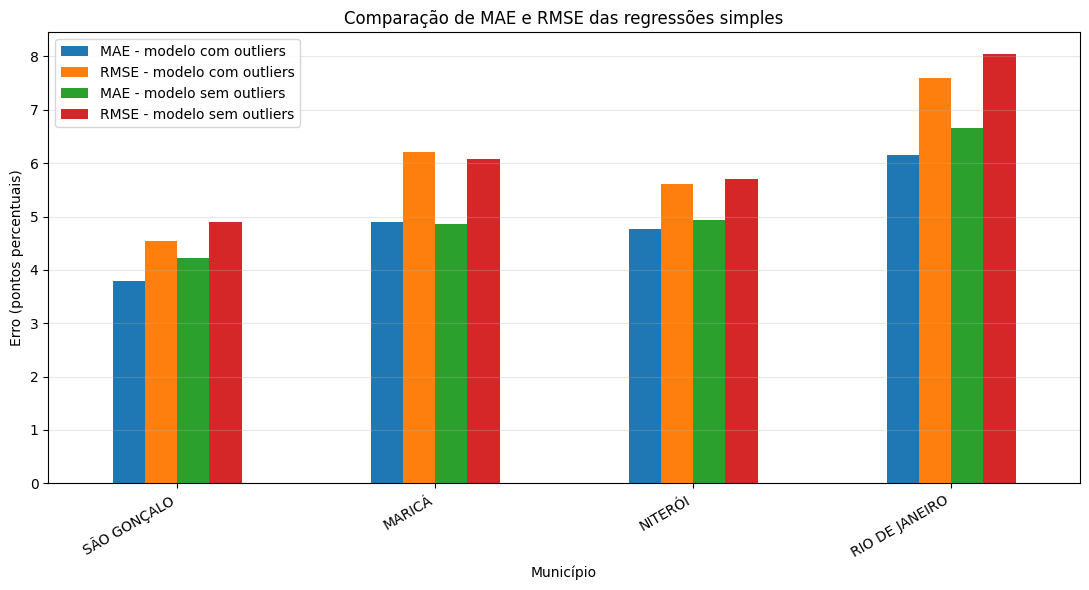

In [45]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Selecionar as métricas do modelo
metricas_modelo = resultado_modelos[
    ["Cidade", "MAE_teste", "RMSE_teste", "R2_teste"]
].copy()

metricas_modelo = metricas_modelo.rename(columns={
    "MAE_teste": "MAE_modelo",
    "RMSE_teste": "RMSE_modelo",
    "R2_teste": "R2_modelo"
})

# Selecionar as métricas do modelo1
metricas_modelo1 = resultado_modelos1[
    ["Cidade", "MAE_teste", "RMSE_teste", "R2_teste"]
].copy()

metricas_modelo1 = metricas_modelo1.rename(columns={
    "MAE_teste": "MAE_modelo1",
    "RMSE_teste": "RMSE_modelo1",
    "R2_teste": "R2_modelo1"
})

# Unir as tabelas por município
comparacao = metricas_modelo.merge(
    metricas_modelo1,
    on="Cidade",
    how="inner"
)

# Criar tabela organizada com as métricas dos dois modelos
tabela_metricas = comparacao[
    [
        "Cidade",
        "R2_modelo", "RMSE_modelo", "MAE_modelo",
        "R2_modelo1", "RMSE_modelo1", "MAE_modelo1"
    ]
].copy()

tabela_metricas.columns = [
    "Município",
    "R² modelo", "RMSE modelo", "MAE modelo",
    "R² modelo1", "RMSE modelo1", "MAE modelo1"
]

print("Comparação das métricas por município:")
display(tabela_metricas.round(3))

# Gráfico comparativo de MAE e RMSE
grafico = comparacao.set_index("Cidade")[
    ["MAE_modelo", "RMSE_modelo",
     "MAE_modelo1", "RMSE_modelo1"]
]

ax = grafico.plot(kind="bar", figsize=(11, 6))

ax.set_ylabel("Erro (pontos percentuais)")
ax.set_xlabel("Município")
ax.set_title("Comparação de MAE e RMSE das regressões simples")
ax.legend([
    "MAE - modelo com outliers",
    "RMSE - modelo com outliers",
    "MAE - modelo sem outliers",
    "RMSE - modelo sem outliers"
])

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("comparacao_metricas_simples.png", dpi=300, bbox_inches="tight")
plt.show()



Visualizações

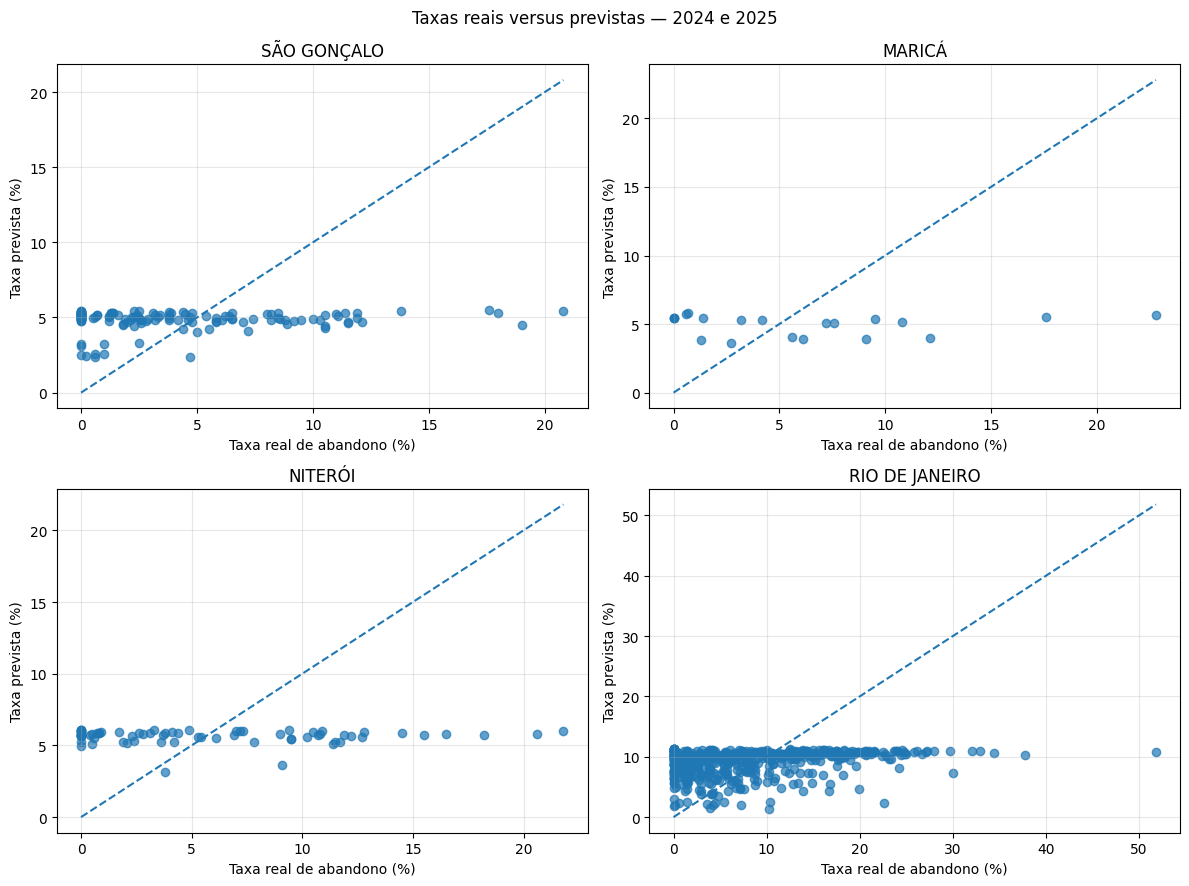

In [42]:
cidades = resultado_previsoes['Nome_do_Municipio'].unique()

fig, eixos = plt.subplots(
    2, 2, figsize=(12, 9), sharex=False, sharey=False
)

for ax, cidade in zip(eixos.flatten(), cidades):
    dados = resultado_previsoes[
        resultado_previsoes['Nome_do_Municipio'] == cidade
    ]

    ax.scatter(
        dados['Abandono_EM_Total'],
        dados['Taxa_Abandono_Prevista'],
        alpha=0.7
    )

    minimo = min(
        dados['Abandono_EM_Total'].min(),
        dados['Taxa_Abandono_Prevista'].min()
    )
    maximo = max(
        dados['Abandono_EM_Total'].max(),
        dados['Taxa_Abandono_Prevista'].max()
    )

    ax.plot([minimo, maximo], [minimo, maximo], '--')

    ax.set_title(cidade)
    ax.set_xlabel('Taxa real de abandono (%)')
    ax.set_ylabel('Taxa prevista (%)')
    ax.grid(True, alpha=0.3)

plt.suptitle('Taxas reais versus previstas — 2024 e 2025')
plt.tight_layout()
plt.savefig("taxas_reais_vs_previstas.png", dpi=300, bbox_inches="tight")
plt.show()

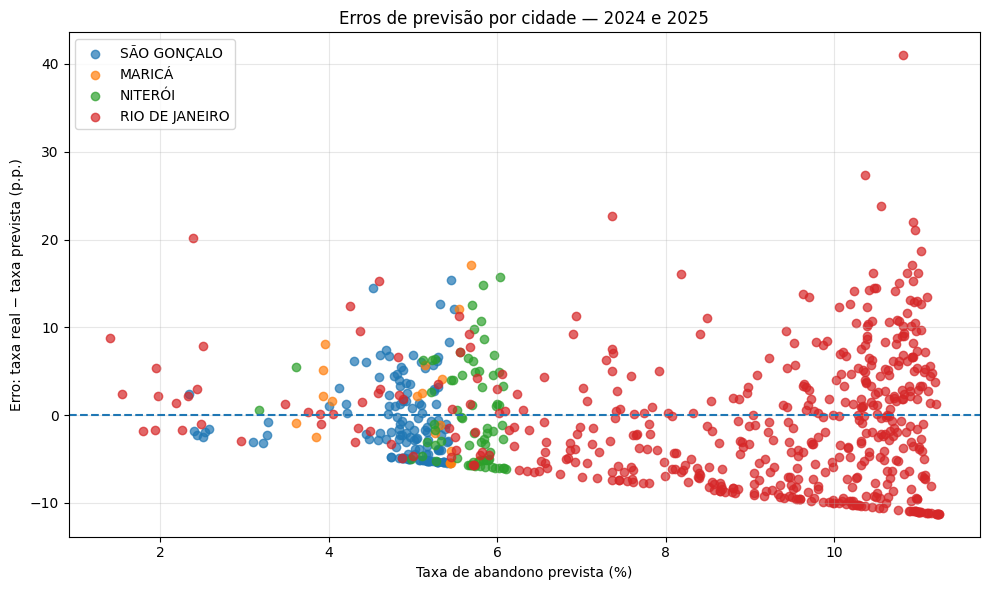

In [44]:
resultado_previsoes['Erro'] = (
    resultado_previsoes['Abandono_EM_Total']
    - resultado_previsoes['Taxa_Abandono_Prevista']
)

fig, ax = plt.subplots(figsize=(10, 6))

for cidade in resultado_previsoes['Nome_do_Municipio'].unique():
    dados = resultado_previsoes[
        resultado_previsoes['Nome_do_Municipio'] == cidade
    ]

    ax.scatter(
        dados['Taxa_Abandono_Prevista'],
        dados['Erro'],
        label=cidade,
        alpha=0.7
    )

ax.axhline(y=0, linestyle='--')
ax.set_xlabel('Taxa de abandono prevista (%)')
ax.set_ylabel('Erro: taxa real − taxa prevista (p.p.)')
ax.set_title('Erros de previsão por cidade — 2024 e 2025')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("erros_por_cidade_simples.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
resumo = resultado_previsoes.groupby('Nome_do_Municipio').agg(
    Taxa_real_media=('Abandono_EM_Total', 'mean'),
    Taxa_prevista_media=('Taxa_Abandono_Prevista', 'mean'),
    Erro_medio=('Erro', 'mean'),
    Erro_absoluto_medio=('Erro', lambda x: x.abs().mean()),
    Desvio_padrao_real=('Abandono_EM_Total', 'std'),
    Numero_observacoes=('Erro', 'count')
).reset_index()

display(resumo.round(2))

,Nome_do_Municipio,Taxa_real_media,Taxa_prevista_media,Erro_medio,Erro_absoluto_medio,Desvio_padrao_real,Numero_observacoes
0,MARICÁ,6.12,4.96,1.17,4.90,6.21,20
1,NITERÓI,5.61,5.65,-0.04,4.77,5.63,72
2,RIO DE JANEIRO,8.19,9.05,-0.86,6.15,7.84,509
3,SÃO GONÇALO,4.08,4.84,-0.76,3.79,4.53,135


##Regressão Linear Múltipla

###Regressões Lineares Múltiplas utilizando One-Hot Encoding, cidade base: Rio de Janeiro

###Reprovação do ano anterior

Incluindo 2020 e 2021 nos anos de treino

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Definir as colunas
col_escola = "Codigo_da_Escola"
col_municipio = "Nome_do_Municipio"
col_ano = "Ano_do_Censo"
col_matriculados = "Quantidade_de_Matriculados_Ensino_Medio"
col_aprovacao = "Aprovacao_EM_Total"
col_reprovacao = "Reprovacao_EM_Total"
col_alvo = "Abandono_EM_Total"

# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)
dados[col_reprovacao] = pd.to_numeric(
    dados[col_reprovacao], errors="coerce"
)
dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a reprovação do ano anterior de cada escola
dados["Reprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_reprovacao].shift(1)
)

# 4. Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
anos_teste = [2024, 2025]

# 5. Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Reprovacao_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Reprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# 6. Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop=["RIO DE JANEIRO"],
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metricas_r = {
    "Modelo": "Matriculados + reprovação anterior (com outliers)",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 10. Criar dataframe com as previsões
resultado_previsoes_r = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes_r["Abandono_Previsto"] = y_pred

resultado_previsoes_r["Erro"] = (
    resultado_previsoes_r[col_alvo]
    - resultado_previsoes_r["Abandono_Previsto"]
)

resultado_previsoes_r["Erro_Absoluto"] = (
    resultado_previsoes_r["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes_r
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)

=== AVALIAÇÃO GERAL ===
Registros de treino: 2892
Registros de teste: 732
MAE:  5.2997
RMSE: 7.0016
R²:   0.0739

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Taxa_Abandono_Prevista,Erro,Erro_Absoluto
0,33051879,SÃO GONÇALO,2024,308.0,12.1,4.677234,7.422766,7.422766
1,33088870,SÃO GONÇALO,2024,83.0,11.9,5.299678,6.600322,6.600322
2,33088870,SÃO GONÇALO,2025,83.0,8.5,5.299678,3.200322,3.200322
3,33088896,SÃO GONÇALO,2024,84.0,0.0,5.296912,-5.296912,5.296912
4,33088896,SÃO GONÇALO,2025,72.0,3.1,5.330109,-2.230109,2.230109
5,33088900,SÃO GONÇALO,2024,361.0,19.0,4.530614,14.469386,14.469386
6,33088900,SÃO GONÇALO,2025,332.0,11.5,4.610840,6.889160,6.889160
7,33088926,SÃO GONÇALO,2024,73.0,1.4,5.327342,-3.927342,3.927342
8,33088926,SÃO GONÇALO,2025,82.0,1.4,5.302445,-3.902445,3.902445
9,33088942,SÃO GONÇALO,2024,140.0,10.5,5.141992,5.358008,5.358008



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,2.798230,5.623651,7.012925,-0.341479
1,NITERÓI,71.0,5.687324,3.830632,4.514548,5.777046,-0.067529
2,RIO DE JANEIRO,506.0,8.184387,6.839830,5.931002,7.657473,0.044566
3,SÃO GONÇALO,135.0,4.076296,2.676205,3.298247,4.603555,-0.040126


Excluindo 2020 e 2021

In [27]:
# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)
dados[col_reprovacao] = pd.to_numeric(
    dados[col_reprovacao], errors="coerce"
)
dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a reprovação do ano anterior de cada escola
dados["Reprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_reprovacao].shift(1)
)

# 4. Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2022, 2023]
anos_teste = [2024, 2025]

# 5. Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Reprovacao_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Reprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# 6. Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop=["RIO DE JANEIRO"],
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo0.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo0.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metricas_r0 = {
    "Modelo": "Matriculados + reprovação anterior (sem outliers)",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 10. Criar dataframe com as previsões
resultado_previsoes_r0 = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes_r0["Abandono_Previsto"] = y_pred

resultado_previsoes_r0["Erro"] = (
    resultado_previsoes_r0[col_alvo]
    - resultado_previsoes_r0["Abandono_Previsto"]
)

resultado_previsoes_r0["Erro_Absoluto"] = (
    resultado_previsoes_r0["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes_r0.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes_r0
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)


=== AVALIAÇÃO GERAL ===
Registros de treino: 2170
Registros de teste: 732
MAE:  5.8747
RMSE: 7.1910
R²:   0.0231

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,6.578447,5.521553,5.521553
17,33053910,MARICÁ,2024,1373.0,12.1,2.743352,9.356648,9.356648
18,33053910,MARICÁ,2025,1443.0,1.3,2.307309,-1.007309,1.007309
28,33053952,MARICÁ,2024,390.0,0.0,6.832382,-6.832382,6.832382
29,33053952,MARICÁ,2025,381.0,0.0,6.668706,-6.668706,6.668706
37,33053995,MARICÁ,2024,170.0,0.6,7.824470,-7.224470,7.224470
38,33053995,MARICÁ,2025,152.0,0.7,8.176939,-7.476939,7.476939
48,33054177,MARICÁ,2024,651.0,7.2,5.976267,1.223733,1.223733
49,33054177,MARICÁ,2025,606.0,7.6,6.424887,1.175113,1.175113
59,33054185,MARICÁ,2024,586.0,10.8,5.813296,4.986704,4.986704



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,5.709517,5.253840,6.286411,-0.077931
1,NITERÓI,71.0,5.687324,6.394958,4.770110,5.511586,0.028324
2,RIO DE JANEIRO,506.0,8.184387,10.617231,6.574377,7.954518,-0.030997
3,SÃO GONÇALO,135.0,4.076296,5.501520,3.924979,4.625014,-0.049846


###Aprovação do ano anterior

Incluindo 2020 e 2021 nos anos de treino

In [26]:
# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)
dados[col_aprovacao] = pd.to_numeric(
    dados[col_aprovacao], errors="coerce"
)
dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a reprovação do ano anterior de cada escola
dados["Aprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_aprovacao].shift(1)
)

# 4. Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
anos_teste = [2024, 2025]

# 5. Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Aprovacao_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Aprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# 6. Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop=["RIO DE JANEIRO"],
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo0.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo0.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metricas_a = {
    "Modelo": "Matriculados + aprovação anterior (com outliers)",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 10. Criar dataframe com as previsões
resultado_previsoes_a = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes_a["Abandono_Previsto"] = y_pred

resultado_previsoes_a["Erro"] = (
    resultado_previsoes_a[col_alvo]
    - resultado_previsoes_a["Abandono_Previsto"]
)

resultado_previsoes_a["Erro_Absoluto"] = (
    resultado_previsoes_a["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes_a.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes_a
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)


=== AVALIAÇÃO GERAL ===
Registros de treino: 2892
Registros de teste: 732
MAE:  4.8464
RMSE: 6.3057
R²:   0.2488

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,7.535117,4.564883,4.564883
17,33053910,MARICÁ,2024,1373.0,12.1,2.587102,9.512898,9.512898
18,33053910,MARICÁ,2025,1443.0,1.3,2.312532,-1.012532,1.012532
28,33053952,MARICÁ,2024,390.0,0.0,3.959465,-3.959465,3.959465
29,33053952,MARICÁ,2025,381.0,0.0,3.351767,-3.351767,3.351767
37,33053995,MARICÁ,2024,170.0,0.6,4.980267,-4.380267,4.380267
38,33053995,MARICÁ,2025,152.0,0.7,5.175368,-4.475368,4.475368
48,33054177,MARICÁ,2024,651.0,7.2,4.751079,2.448921,2.448921
49,33054177,MARICÁ,2025,606.0,7.6,5.163486,2.436514,2.436514
59,33054185,MARICÁ,2024,586.0,10.8,3.394754,7.405246,7.405246



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,4.342235,4.616296,5.542715,0.162026
1,NITERÓI,71.0,5.687324,4.813659,3.879553,4.858004,0.245109
2,RIO DE JANEIRO,506.0,8.184387,7.856487,5.501372,6.978430,0.206503
3,SÃO GONÇALO,135.0,4.076296,3.516204,2.933976,4.013171,0.209549


Excluindo 2020 e 2021

In [25]:
# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)
dados[col_aprovacao] = pd.to_numeric(
    dados[col_aprovacao], errors="coerce"
)
dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a reprovação do ano anterior de cada escola
dados["Aprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_aprovacao].shift(1)
)

# 4. Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2022, 2023]
anos_teste = [2024, 2025]

# 5. Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Aprovacao_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Aprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# 6. Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop=["RIO DE JANEIRO"],
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo0.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo0.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metricas_a0 = {
    "Modelo": "Matriculados + aprovação anterior (sem outliers)",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 10. Criar dataframe com as previsões
resultado_previsoes_a0 = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes_a0["Abandono_Previsto"] = y_pred

resultado_previsoes_a0["Erro"] = (
    resultado_previsoes_a0[col_alvo]
    - resultado_previsoes_a0["Abandono_Previsto"]
)

resultado_previsoes_a0["Erro_Absoluto"] = (
    resultado_previsoes_a0["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes_a0.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes_a0
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)


=== AVALIAÇÃO GERAL ===
Registros de treino: 2170
Registros de teste: 732
MAE:  5.6763
RMSE: 6.9277
R²:   0.0933

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,11.170398,0.929602,0.929602
17,33053910,MARICÁ,2024,1373.0,12.1,5.249090,6.850910,6.850910
18,33053910,MARICÁ,2025,1443.0,1.3,5.329067,-4.029067,4.029067
28,33053952,MARICÁ,2024,390.0,0.0,6.642255,-6.642255,6.642255
29,33053952,MARICÁ,2025,381.0,0.0,6.274556,-6.274556,6.274556
37,33053995,MARICÁ,2024,170.0,0.6,7.854764,-7.254764,7.254764
38,33053995,MARICÁ,2025,152.0,0.7,8.497176,-7.797176,7.797176
48,33054177,MARICÁ,2024,651.0,7.2,7.731333,-0.531333,0.531333
49,33054177,MARICÁ,2025,606.0,7.6,8.638699,-1.038699,1.038699
59,33054185,MARICÁ,2024,586.0,10.8,5.997105,4.802895,4.802895



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,7.436413,4.484285,5.283447,0.238587
1,NITERÓI,71.0,5.687324,7.300683,4.263306,4.871582,0.240884
2,RIO DE JANEIRO,506.0,8.184387,11.629064,6.418127,7.721370,0.028555
3,SÃO GONÇALO,135.0,4.076296,6.278041,3.815572,4.488662,0.011144


Abandono do ano anterior

Incluindo 2020 e 2021 nos anos de treino

In [23]:
# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)

dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a reprovação do ano anterior de cada escola
dados["Abandono_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_alvo].shift(1)
)

# 4. Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
anos_teste = [2024, 2025]

# 5. Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Abandono_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Abandono_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# 6. Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop=["RIO DE JANEIRO"],
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo0.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo0.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metricas_ab = {
    "Modelo": "Matriculados + abandono anterior (com outliers)",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 10. Criar dataframe com as previsões
resultado_previsoes_ab = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes_ab["Abandono_Previsto"] = y_pred

resultado_previsoes_ab["Erro"] = (
    resultado_previsoes_ab[col_alvo]
    - resultado_previsoes_ab["Abandono_Previsto"]
)

resultado_previsoes_ab["Erro_Absoluto"] = (
    resultado_previsoes_ab["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes_ab.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes_ab
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)


=== AVALIAÇÃO GERAL ===
Registros de treino: 2892
Registros de teste: 732
MAE:  4.5731
RMSE: 6.0087
R²:   0.3179

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,5.808275,6.291725,6.291725
17,33053910,MARICÁ,2024,1373.0,12.1,3.018183,9.081817,9.081817
18,33053910,MARICÁ,2025,1443.0,1.3,2.918834,-1.618834,1.618834
28,33053952,MARICÁ,2024,390.0,0.0,3.265228,-3.265228,3.265228
29,33053952,MARICÁ,2025,381.0,0.0,2.601711,-2.601711,2.601711
37,33053995,MARICÁ,2024,170.0,0.6,4.308177,-3.708177,3.708177
38,33053995,MARICÁ,2025,152.0,0.7,3.359455,-2.659455,2.659455
48,33054177,MARICÁ,2024,651.0,7.2,4.431132,2.768868,2.768868
49,33054177,MARICÁ,2025,606.0,7.6,3.862455,3.737545,3.737545
59,33054185,MARICÁ,2024,586.0,10.8,3.418194,7.381806,7.381806



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,3.792638,4.365931,5.494753,0.176466
1,NITERÓI,71.0,5.687324,3.856718,4.067214,5.228368,0.125619
2,RIO DE JANEIRO,506.0,8.184387,7.414749,5.090161,6.541564,0.302743
3,SÃO GONÇALO,135.0,4.076296,3.078013,2.931630,4.065268,0.188894


Excluindo os anos de 2020 e 2021 dos anos de treino

In [22]:
# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)

dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a reprovação do ano anterior de cada escola
dados["Abandono_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_alvo].shift(1)
)

# 4. Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2022, 2023]
anos_teste = [2024, 2025]

# 5. Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Abandono_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Abandono_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# 6. Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop=["RIO DE JANEIRO"],
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo0.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo0.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metricas_ab0 = {
    "Modelo": "Matriculados + abandono anterior (sem outliers)",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 10. Criar dataframe com as previsões
resultado_previsoes_ab0 = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes_ab0["Abandono_Previsto"] = y_pred

resultado_previsoes_ab0["Erro"] = (
    resultado_previsoes_ab0[col_alvo]
    - resultado_previsoes_ab0["Abandono_Previsto"]
)

resultado_previsoes_ab0["Erro_Absoluto"] = (
    resultado_previsoes_ab0["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes_ab0.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes_ab0
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)


=== AVALIAÇÃO GERAL ===
Registros de treino: 2170
Registros de teste: 732
MAE:  5.1359
RMSE: 6.2680
R²:   0.2578

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,8.919354,3.180646,3.180646
17,33053910,MARICÁ,2024,1373.0,12.1,5.792836,6.307164,6.307164
18,33053910,MARICÁ,2025,1443.0,1.3,6.075330,-4.775330,4.775330
28,33053952,MARICÁ,2024,390.0,0.0,5.725936,-5.725936,5.725936
29,33053952,MARICÁ,2025,381.0,0.0,5.282607,-5.282607,5.282607
37,33053995,MARICÁ,2024,170.0,0.6,6.929337,-6.329337,6.329337
38,33053995,MARICÁ,2025,152.0,0.7,6.130776,-5.430776,5.430776
48,33054177,MARICÁ,2024,651.0,7.2,7.262869,-0.062869,0.062869
49,33054177,MARICÁ,2025,606.0,7.6,6.922923,0.677077,0.677077
59,33054185,MARICÁ,2024,586.0,10.8,5.988739,4.811261,4.811261



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,6.686334,4.051981,4.837851,0.361604
1,NITERÓI,71.0,5.687324,6.219371,4.147255,4.772883,0.271332
2,RIO DE JANEIRO,506.0,8.184387,10.928479,5.745499,6.925159,0.218572
3,SÃO GONÇALO,135.0,4.076296,5.717510,3.531602,4.222197,0.125064


###Reprovação do ano anterior + Abandono do ano anterior

In [21]:
# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)

dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a variável do ano anterior de cada escola
dados["Abandono_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_alvo].shift(1)
)
dados["Reprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_reprovacao].shift(1)
)

# Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
anos_teste = [2024, 2025]

# Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Abandono_Ano_Anterior",
    "Reprovacao_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Abandono_Ano_Anterior",
        "Reprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop=["RIO DE JANEIRO"],
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo0.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo0.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

metricas_ar = {
    "Modelo": "Matriculados + abandono anterior + reprovação anterior (com outliers)",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

# 10. Criar dataframe com as previsões
resultado_previsoes_ar = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes_ar["Abandono_Previsto"] = y_pred

resultado_previsoes_ar["Erro"] = (
    resultado_previsoes_ar[col_alvo]
    - resultado_previsoes_ar["Abandono_Previsto"]
)

resultado_previsoes_ar["Erro_Absoluto"] = (
    resultado_previsoes_ar["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes_ar.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes_ar
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)

=== AVALIAÇÃO GERAL ===
Registros de treino: 2892
Registros de teste: 732
MAE:  4.5408
RMSE: 5.9151
R²:   0.3390

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,7.349264,4.750736,4.750736
17,33053910,MARICÁ,2024,1373.0,12.1,3.429974,8.670026,8.670026
18,33053910,MARICÁ,2025,1443.0,1.3,3.385948,-2.085948,2.085948
28,33053952,MARICÁ,2024,390.0,0.0,3.514436,-3.514436,3.514436
29,33053952,MARICÁ,2025,381.0,0.0,2.837753,-2.837753,2.837753
37,33053995,MARICÁ,2024,170.0,0.6,4.597509,-3.997509,3.997509
38,33053995,MARICÁ,2025,152.0,0.7,4.086263,-3.386263,3.386263
48,33054177,MARICÁ,2024,651.0,7.2,4.945424,2.254576,2.254576
49,33054177,MARICÁ,2025,606.0,7.6,4.795843,2.804157,2.804157
59,33054185,MARICÁ,2024,586.0,10.8,3.507652,7.292348,7.292348



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,4.379445,4.247180,5.138586,0.279768
1,NITERÓI,71.0,5.687324,4.433071,3.823997,4.823407,0.255823
2,RIO DE JANEIRO,506.0,8.184387,7.827806,5.109836,6.500917,0.311381
3,SÃO GONÇALO,135.0,4.076296,3.443748,2.828555,3.894237,0.255707


Excluindo 2020 e 2021 dos anos de treino:

In [19]:
# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)

dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a variável do ano anterior de cada escola
dados["Abandono_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_alvo].shift(1)
)
dados["Reprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_reprovacao].shift(1)
)

# Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2022, 2023]
anos_teste = [2024, 2025]

# Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Abandono_Ano_Anterior",
    "Reprovacao_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Abandono_Ano_Anterior",
        "Reprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop=["RIO DE JANEIRO"],
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo0.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo0.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

metricas_ar0 = {
    "Modelo": "Matriculados + abandono anterior + reprovação anterior (sem outliers)",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

# 10. Criar dataframe com as previsões
resultado_previsoes_ar0 = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes_ar0["Abandono_Previsto"] = y_pred

resultado_previsoes_ar0["Erro"] = (
    resultado_previsoes_ar0[col_alvo]
    - resultado_previsoes_ar0["Abandono_Previsto"]
)

resultado_previsoes_ar0["Erro_Absoluto"] = (
    resultado_previsoes_ar0["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes_ar0.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes_ar0
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)

=== AVALIAÇÃO GERAL ===
Registros de treino: 2170
Registros de teste: 732
MAE:  5.2442
RMSE: 6.3996
R²:   0.2263

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,10.729540,1.370460,1.370460
17,33053910,MARICÁ,2024,1373.0,12.1,6.233851,5.866149,5.866149
18,33053910,MARICÁ,2025,1443.0,1.3,6.579230,-5.279230,5.279230
28,33053952,MARICÁ,2024,390.0,0.0,5.962467,-5.962467,5.962467
29,33053952,MARICÁ,2025,381.0,0.0,5.492905,-5.492905,5.492905
37,33053995,MARICÁ,2024,170.0,0.6,7.222231,-6.622231,6.622231
38,33053995,MARICÁ,2025,152.0,0.7,6.938716,-6.238716,6.238716
48,33054177,MARICÁ,2024,651.0,7.2,7.833815,-0.633815,0.633815
49,33054177,MARICÁ,2025,606.0,7.6,7.990173,-0.390173,0.390173
59,33054185,MARICÁ,2024,586.0,10.8,6.035978,4.764022,4.764022



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,7.337325,4.042608,4.791559,0.373762
1,NITERÓI,71.0,5.687324,6.773054,3.998724,4.585566,0.327404
2,RIO DE JANEIRO,506.0,8.184387,11.390471,5.899734,7.107481,0.176884
3,SÃO GONÇALO,135.0,4.076296,6.079119,3.620089,4.273909,0.103501


#Visualizações das métricas

In [41]:
df_metricas = pd.DataFrame([
    metricas_ar0,
    metricas_ar,
    metricas_ab0,
    metricas_ab,
    metricas_r0,
    metricas_r,
    metricas_a0,
    metricas_a,

])

df_metricas["Outliers"] = [
    "Sem outliers",
    "Com outliers",
    "Sem outliers",
    "Com outliers",
    "Sem outliers",
    "Com outliers",
    "Sem outliers",
    "Com outliers"
]

df_metricas.to_csv(
    "metricas_modelos.csv",
    index=False,
    sep=";",
    decimal=","
)

display(df_metricas)

,Modelo,MAE,RMSE,R2,Outliers
0,Matriculados + abandono anterior + reprovação ...,5.244179,6.399637,0.226284,Sem outliers
1,Matriculados + abandono anterior + reprovação ...,4.540818,5.915128,0.339004,Com outliers
2,Matriculados + abandono anterior (sem outliers),5.135907,6.268013,0.257784,Sem outliers
3,Matriculados + abandono anterior (com outliers),4.573063,6.008707,0.317924,Com outliers
4,Matriculados + reprovação anterior (sem outliers),5.874674,7.190970,0.023110,Sem outliers
5,Matriculados + reprovação anterior (com outliers),5.299667,7.001608,0.073882,Com outliers
6,Matriculados + aprovação anterior (sem outliers),5.676304,6.927688,0.093334,Sem outliers
7,Matriculados + aprovação anterior (com outliers),4.846387,6.305706,0.248830,Com outliers


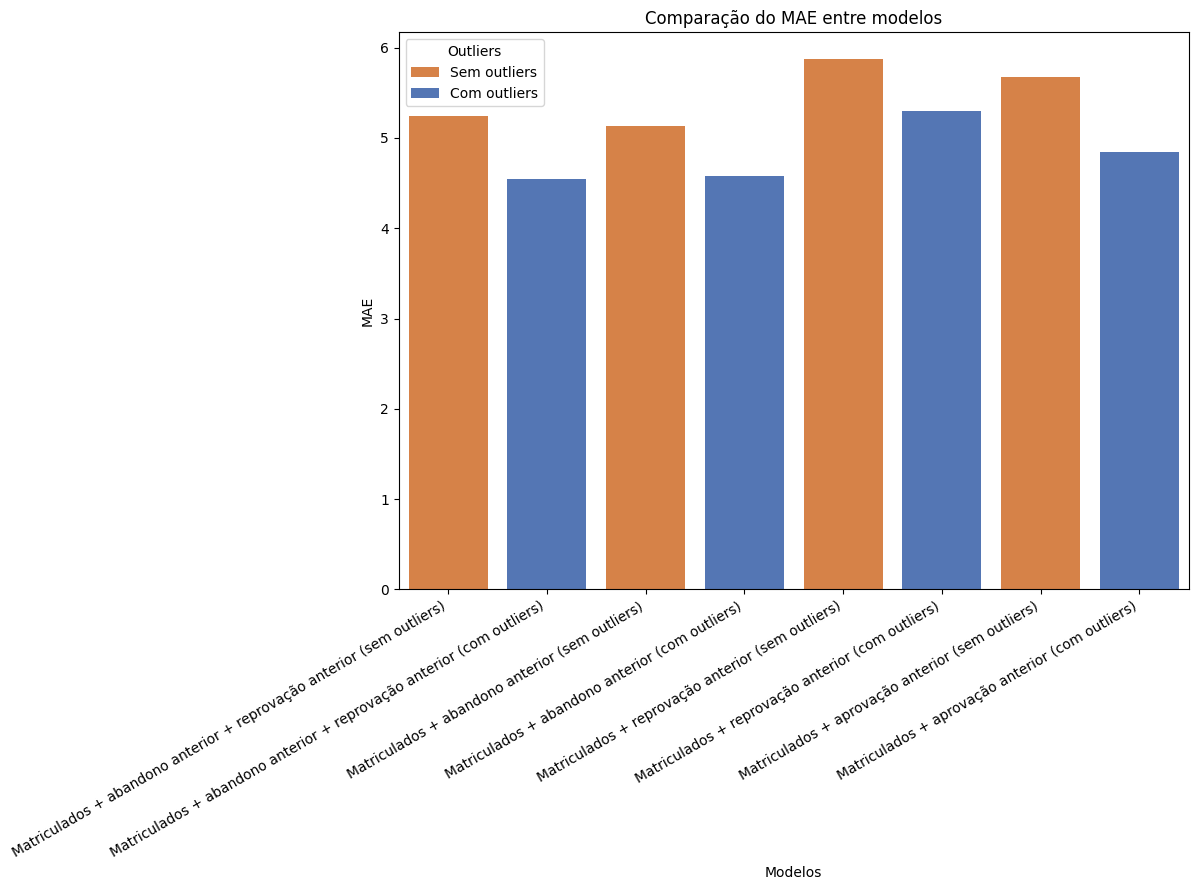

In [38]:
paleta = {
    "Com outliers": "#4472C4",
    "Sem outliers": "#ED7D31"
}

plt.figure(figsize=(12, 9))

sns.barplot(
    data=df_metricas,
    x="Modelo",
    y="MAE",
    hue="Outliers",
    palette=paleta
)

plt.title("Comparação do MAE entre modelos")
plt.xlabel("Modelos")
plt.ylabel("MAE")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("grafico_mae.png", dpi=300, bbox_inches="tight")
plt.show()

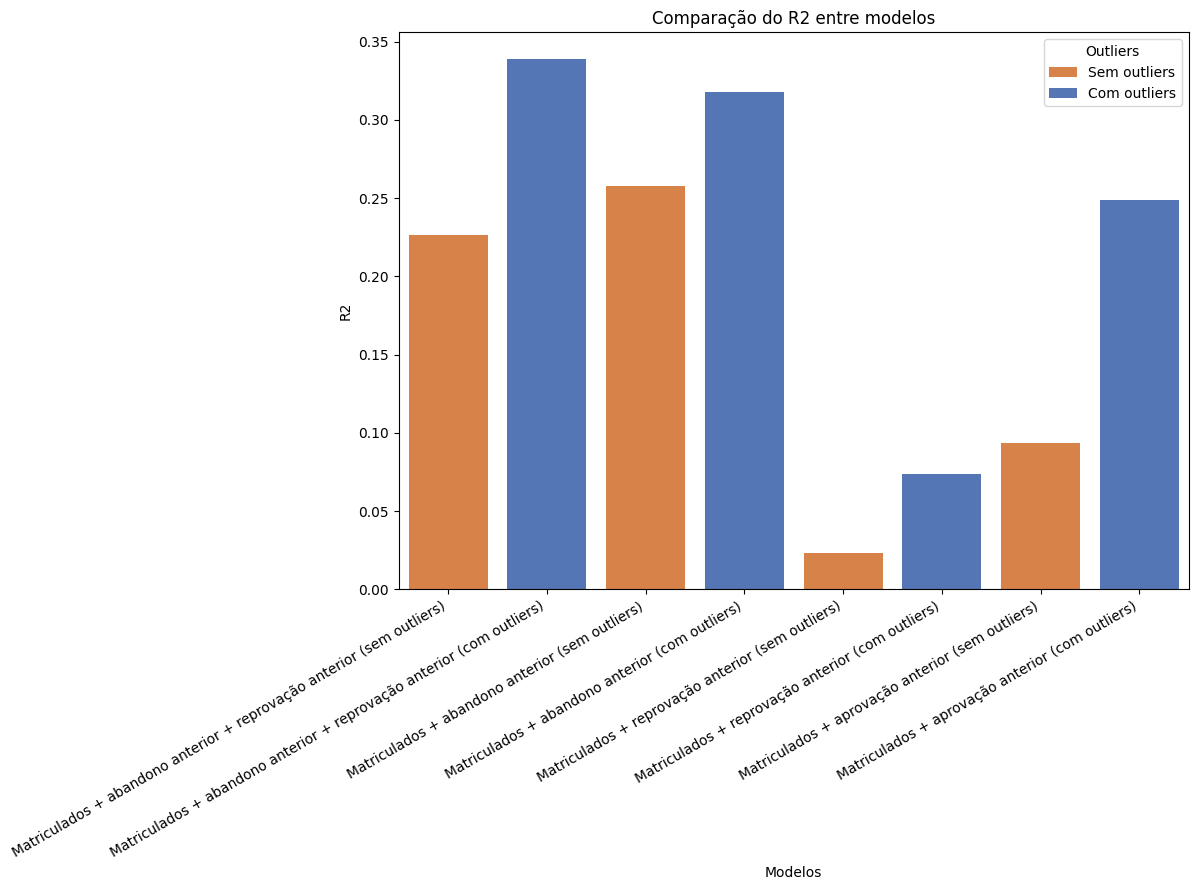

In [39]:
paleta = {
    "Com outliers": "#4472C4",
    "Sem outliers": "#ED7D31"
}

plt.figure(figsize=(12, 9))

sns.barplot(
    data=df_metricas,
    x="Modelo",
    y="R2",
    hue="Outliers",
    palette=paleta
)

plt.title("Comparação do R2 entre modelos")
plt.xlabel("Modelos")
plt.ylabel("R2")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("grafico_R2.png", dpi=300, bbox_inches="tight")
plt.show()

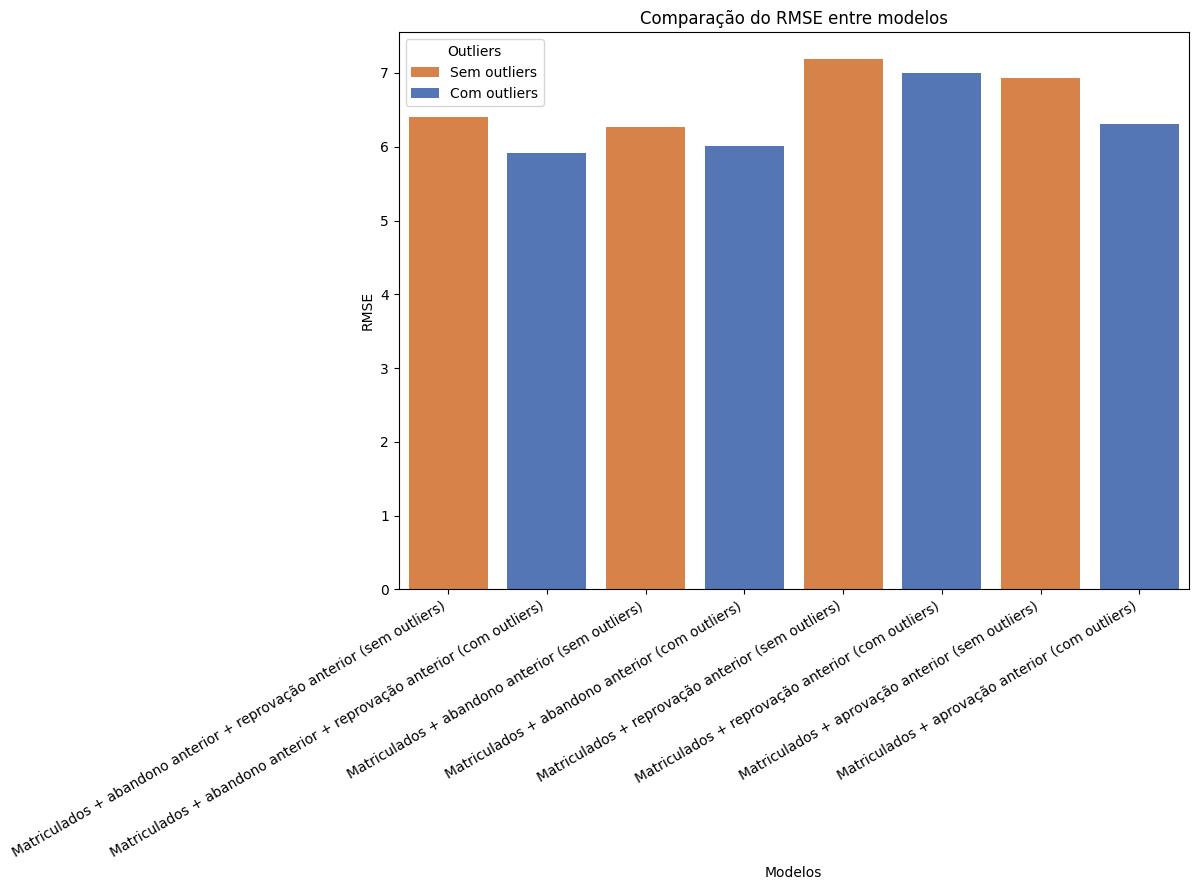

In [40]:
plt.figure(figsize=(12, 9))

sns.barplot(
    data=df_metricas,
    x="Modelo",
    y="RMSE",
    hue="Outliers",
    palette=paleta
)

plt.title("Comparação do RMSE entre modelos")
plt.xlabel("Modelos")
plt.ylabel("RMSE")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("grafico_RMSE.png", dpi=300, bbox_inches="tight")
plt.show()